In [1]:
import os, json
import pandas as pd

In [2]:
# creating a dataframe of all of the annotator profiles
SCORED_ANNOTATOR_DIR = "annotation_artefacts/final_annotator_objects"
os.makedirs(SCORED_ANNOTATOR_DIR, exist_ok=True)

df_list = []
for annfilename in os.listdir(SCORED_ANNOTATOR_DIR):
    annotator_filepath = os.path.join(SCORED_ANNOTATOR_DIR, annfilename)
    with open(annotator_filepath, "r") as  ao:
        annotator_object = json.load(ao)
    prompt_lengths = []
    prompt_type_freq_table = {
        "imperative" : 0,
        "interrogative" : 0,
        "declarative" : 0,
    }
    prompt_grammaticality = {
        "grammar_correct" : 0,
        "grammar_incorrect" : 0,
    }

    for v in annotator_object["answers"].values():
        if v["answer"]:
            prompt_lengths.append(v["sentence_length"])
            prompt_type_freq_table[v["sentence_type"]] += 1
            prompt_grammaticality[f"grammar_{v["grammaticality"]}"] += 1

    df_list.append({
        "id" : annotator_object["id"],
        **annotator_object["profile"],
        "sum_sentence_lengths" : sum(prompt_lengths),
        **prompt_type_freq_table,
        **prompt_grammaticality,
    })

df_list = sorted(df_list, key=lambda x: x["id"])
df = pd.DataFrame(df_list)

In [3]:
df

,id,employment_sector,race,education,sex,age,language,nationality_group,sum_sentence_lengths,imperative,interrogative,declarative,grammar_correct,grammar_incorrect
0,0,Humanities,White,Graduate,female,31-40,L1,North America,321,20,6,0,25,1
1,1,Humanities,Asian,Postgraduate,female,18-30,None,North America,331,22,2,0,22,2
2,2,Humanities,White,Graduate,female,18-30,None,North America,646,22,5,0,22,5
3,3,Engineering-STEM,White,Graduate,female,31-40,L1,Europe,397,7,20,0,19,8
4,4,Humanities,White,Graduate,female,41-50,L1,North America,542,19,10,0,26,3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
94,100,Engineering-STEM,White,Graduate,male,41-50,None,North America,557,21,4,0,21,4
95,101,Health-STEM,Black,Postgraduate,female,41-50,L1,North America,448,19,9,0,23,5
96,103,Engineering-STEM,White,Graduate,male,41-50,L1,Europe,470,6,21,0,22,5
97,104,Engineering-STEM,White,Graduate,male,41-50,L1,North America,550,12,6,5,19,4


In [4]:
from src.classes.AnnotatorManager import AnnotatorManager
from src.utils.viz_utils import plot_histogram_by_category, plot_grouped_bar_chart
import matplotlib.pyplot as plt
import numpy as np

In [5]:
# aggregates = {
#     "sum_sentence_lengths": {
#         "employment_sector" : [...],
#         "race" : [...],
#         "education" : [...],
#     },
#     "interrogative",
#     imperative	interrogative	declarative	grammar_correct	grammar_incorrect
# }
# aggregates:

profile_columns = ["employment_sector", "race", "education", "sex", "age", "language", "nationality_group"]
for pc in profile_columns:
    for group_value, group_df in df.groupby(pc):
        print(f"\nGroup: {pc} = {group_value}")
        print(f"Group members = {len(group_df)}")
        others = [col for col in profile_columns if col != pc]
        for oc in others:
            top_value = group_df[oc].value_counts(normalize=True).idxmax()
            top_ratio = group_df[oc].value_counts(normalize=True).max()
            if top_ratio > 0.5:
                print(f"  Column {oc} dominated by '{top_value}' with {top_ratio:.2f}")


Group: employment_sector = Engineering-STEM
Group members = 38
  Column sex dominated by 'male' with 0.58
  Column language dominated by 'L1' with 0.57

Group: employment_sector = Health-STEM
Group members = 26
  Column race dominated by 'White' with 0.60
  Column education dominated by 'Postgraduate' with 0.58
  Column sex dominated by 'female' with 0.73
  Column language dominated by 'L1' with 1.00

Group: employment_sector = Humanities
Group members = 35
  Column race dominated by 'White' with 0.52
  Column sex dominated by 'male' with 0.51
  Column language dominated by 'L1' with 0.59

Group: race = Asian
Group members = 26
  Column employment_sector dominated by 'Engineering-STEM' with 0.58
  Column sex dominated by 'male' with 0.65
  Column age dominated by '18-30' with 0.85
  Column language dominated by 'L2' with 0.87
  Column nationality_group dominated by 'Asia' with 0.72

Group: race = Black
Group members = 18
  Column education dominated by 'Postgraduate' with 0.89
  Colum

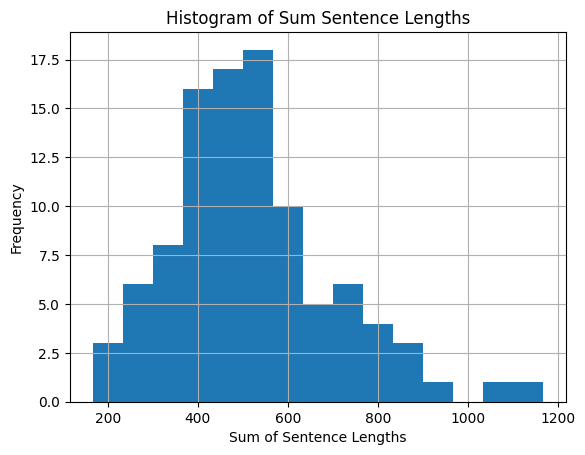

In [13]:
df['sum_sentence_lengths'].hist(bins=15)
plt.xlabel('Sum of Sentence Lengths')
plt.ylabel('Frequency')
plt.title('Histogram of Sum Sentence Lengths')
plt.show()

In [7]:
N = len(aggregates["sum_sentence_lengths"])
fig, axes = plt.subplots(N, 2, figsize=(12, 4 * N))

column_labels = ['Sentence Length Histogram', 'Prompt Sentence Type']
for col, label in enumerate(column_labels):
    axes[0, col].set_title(label, fontsize=9)

# Row labels
row_labels = [k for k in aggregates["sum_sentence_lengths"].keys()]
for row, label in enumerate(row_labels):
    axes[row, 0].set_ylabel(label, fontsize=10, rotation=90)


nrows, ncols = axes.shape
for i, j in np.ndindex(nrows, ncols):
    ax = axes[i, j]
    demo_graph = list(aggregates["sum_sentence_lengths"].keys())[i]
    if j == 0:
        data = aggregates['sum_sentence_lengths'][demo_graph]
        plot_histogram_by_category(data, ax)
    else:
        data = {}
        for d in aggregates["interrogative"][demo_graph].keys():
            data[d] = {}
            for senttype in ["imperative", "interrogative", "declarative"]:
                data[d][senttype] = aggregates[senttype][demo_graph][d]
        plot_grouped_bar_chart(data, ax)

NameError: name 'aggregates' is not defined

In [ ]:
from src.classes.Questions import Questions

questions = Questions().get_questions()
MODEL_TO_VIZ = "Qwen25_7B_Inst"

# creating a dataframe of all of the annotator profiles
SCORED_ANNOTATOR_DIR = "annotation_artefacts/scored_passed_annotators"

downstream_score_df_list = []
for annfilename in os.listdir(SCORED_ANNOTATOR_DIR):
    annotator_filepath = os.path.join(SCORED_ANNOTATOR_DIR, annfilename)
    with open(annotator_filepath, "r") as  ao:
        annotator_object = json.load(ao)
    
    downstream_scores = {}
    for question_key, values in annotator_object["answers"].items():
        if values["answer"] == None:
            continue
        for qid, score_s in values["downstream_scores"][MODEL_TO_VIZ].items():
            postfix = questions[question_key]["metrics"][0] # first metric entry is by convention default
            matching_keys = [k for k in score_s if k.endswith(f"{postfix}_score")]
            if not matching_keys:
                raise ValueError(f"No key ends with '{postfix}' for qid {qid}")
            correct_key = matching_keys[0]
            downstream_scores[f"{qid}-sentence_type"] = values["sentence_type"]
            downstream_scores[f"{qid}-sentence_length"] = values["sentence_length"]
            downstream_scores[correct_key] = score_s[correct_key]

    downstream_score_df_list.append({
        "id" : annotator_object["id"],
        **downstream_scores,
    })

score_df_list = sorted(downstream_score_df_list, key=lambda x: x["id"])
df = pd.DataFrame(score_df_list)
df.to_csv(f"lm_harness_processed/raw-{MODEL_TO_VIZ}.csv")

/Users/rayendito/miniconda3/envs/pietorch/lib/python3.12/site-packages/scipy/stats/_distn_infrastructure.py:2027: RuntimeWarning: divide by zero encountered in divide
  x = np.asarray((x - loc)/scale, dtype=dtyp)
/Users/rayendito/Documents/prompt-fairness/src/utils/viz_utils.py:35: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()




In [ ]:
cols = [col for col in df.columns if col != 'id']
number_of_tasks = len(cols)//3
fig, axes = plt.subplots(number_of_tasks, 1, figsize=(10, 4 * number_of_tasks))
assert len(axes) == len(range(0, len(cols), 3))

length_correlation_df = []
for i in range(0, len(cols), 3):
    chunk_cols = cols[i:i+3]
    subset_df = df[chunk_cols].dropna()
    task_name = "-".join(chunk_cols[-1].split("-")[:-2])
    
    
    prompt_type_freqtable = {}
    for _, row in subset_df.iterrows():
        ptype = row.to_dict()[chunk_cols[0]]
        score = row.to_dict()[chunk_cols[-1]]
        if ptype in prompt_type_freqtable:
            prompt_type_freqtable[ptype].append(score)
        else:
            prompt_type_freqtable[ptype] = [score]
    
    prompt_type_freqtable = dict(sorted(prompt_type_freqtable.items()))

    axes[i].set_ylabel(task_name, fontsize=10, rotation=90)
    bin_edges=np.arange(0,1,10)
    plot_histogram_by_category(prompt_type_freqtable, axes[i], bin_edges=bin_edges)
    break
    pearson_corr = np.corrcoef(subset_df[chunk_cols[1]],
                               subset_df[chunk_cols[2]])
    length_correlation_df.append({
        "task_name" : task_name,
        f"{MODEL_TO_VIZ}-length_correlation" : pearson_corr[0][-1]
    })

lcdf = pd.DataFrame(length_correlation_df)
lcdf.to_csv(f"lm_harness_processed/prompt_length_correlation-{MODEL_TO_VIZ}.csv")